# 07 · The search

NSGA-II over the PyNAS search space (`[Space]` of the configuration), `[Search] population` = 50 candidates per generation, `[Search] generations` = 3. For every candidate, before any training:

- the weights in FP16 over 5 MB → infeasible, nothing compiled;
- ONNX → FP16 IR (OpenVINO 2022.3.1 Model Optimizer) → compiled for MYRIAD with `compile_tool`; not compiled, IR over 5 MB, or IR layer types missing from the ArgOS list → infeasible;
- predicted Myriad X latency (nn-Meter).

An infeasible candidate is never trained; another is drawn. The feasible ones are trained (10,000 batches of 16) in FP16 mixed precision with distillation from the teacher, BatchNorm folded into the convolutions for the last 20% of the steps, and scored with the folded network in FP16 on the search split. Selection on (fresh-burn IoU ↑, latency ↓). The winner: the best fitness of all trained candidates, ties broken by latency (`[Final] pick`), a rule fixed before the search runs.

The search runs in a background process of its own; this notebook can be closed while it runs, and every cell that reads results can run at any time.

In [1]:
# [1] setup
%cd ~/projects/iride_onboard-burnscar-mapper
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
for p in (os.path.join(os.getcwd(), "pyqnas", "src"), os.getcwd()):
    if p not in sys.path:
        sys.path.insert(0, p)
import pynas
from pynas import config, report
from pynas.hardware import myriad
from pynas.search import driver

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False})
CONFIG = Path("configs/burnscar.ini")
cfg = config.load(CONFIG)
OUT = Path(cfg.get("Run", "out")) / "search"
soft = Path(cfg.get("Data", "pool")) / f"{cfg.get('Data', 'train')}_{cfg.get('Data', 'teacher')}.npy"
assert soft.exists(), f"no soft labels ({soft}): run 06_pool_and_teacher first"
st = myriad.status(cfg)
print(f"PyNAS {pynas.__version__}; Myriad tools: {st}; {torch.cuda.device_count()} GPUs")
if not all(st.values()):
    print("missing tools: myriad.setup(cfg) makes them (a few minutes, once per machine)")

/root/projects/iride_onboard-burnscar-mapper
PyNAS 1.0.1; Myriad tools: {'model_optimizer': True, 'compile_tool': True, 'nnmeter': True}; 2 GPUs


## 1. Smoke test

The whole loop at a tiny size on this machine (4 candidates, 2 generations, 300 batches each), into `models/pynas/smoke/`: every stage runs on the real tools before the real search. About 10 minutes. Its results mean nothing and are not used.

In [2]:
# [2] smoke test (in this notebook, about 10 minutes)
SMOKE = Path(cfg.get("Run", "out")) / "smoke"
cfg_smoke = config.with_overrides(cfg, {"Search.population": 4, "Search.generations": 2, "Train.steps": 300,
                                        "Train.log_every": 100})
w = driver.Search(cfg_smoke, SMOKE).run()
print(json.dumps(w, indent=1, default=str))
display(report.generation_summary(SMOKE))

/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


compiling 2 candidates for MYRIAD


/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/jit_utils.py:308: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_node_shape_type_inference(node, params_dict, opset_version)
/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/utils.py:714: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_graph_shape_type_inference(
/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/utils.py:1187: UserWarning: Constant folding

generation 0: 2/4 feasible after 8 draws
compiling 3 candidates for MYRIAD
generation 0: 4/4 feasible after 12 draws
generation 0: training 4 candidates on GPUs [0, 1]
4 run(s) to do, 2 worker(s): GPU 0 (pid 1311461), GPU 1 (pid 1311463); logs in /root/projects/iride_onboard-burnscar-mapper/models/pynas/smoke/runs/log_gpu<k>.txt
2026-10-14 16:12:17   4 waiting
2026-10-14 16:12:37   2 running, 2 waiting
2026-10-14 16:14:37   4 done
generation 0 done; best score 0.1406
compiling 8 candidates for MYRIAD


/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/jit_utils.py:308: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_node_shape_type_inference(node, params_dict, opset_version)
/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/utils.py:714: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_graph_shape_type_inference(
/root/projects/iride_onboard-burnscar-mapper/.venv/lib/python3.12/site-packages/torch/onnx/_internal/torchscript_exporter/utils.py:1187: UserWarning: Constant folding

generation 1: 4/4 feasible after 8 draws
generation 1: training 4 candidates on GPUs [0, 1]
4 run(s) to do, 2 worker(s): GPU 0 (pid 1314995), GPU 1 (pid 1314996); logs in /root/projects/iride_onboard-burnscar-mapper/models/pynas/smoke/runs/log_gpu<k>.txt
2026-10-14 16:14:50   4 waiting
2026-10-14 16:15:10   2 running, 2 waiting
2026-10-14 16:17:10   4 done
generation 1 done; best score 0.1406
winner: E:eb0:3/D:conv:96:2 (score 0.1406202659004285, latency 74.321 ms)
{
 "gen": 0,
 "run": "r_315f0eb70e23",
 "spec": "E:eb0:3/D:conv:96:2",
 "score": 0.1406202659004285,
 "score_pooled": 0.1149893025246042,
 "latency_ms": 74.321,
 "ir_mb": 0.905,
 "params": 400008.0,
 "est_mb": 0.8,
 "minutes": 0.768163514137268,
 "not_finite_steps": 0.0,
 "folded_pairs": 17.0,
 "trained": true,
 "heo_search_fp16_labels_fresh_iou": 0.1149893025246042,
 "heo_search_fp16_labels_mean_iou": 0.3835788141966744,
 "heo_search_fp16_labels_burn_iou": 0.1149893025246042,
 "heo_search_fp16_teacher_fresh_iou": 0.06376816

,gen,tried,infeasible,reasons,trained,best,median
0,0,12,7,weights 5.72 MB in FP16 > 5.0 MB (1); weights 6.81 MB in FP16 > 5.0 MB (1); weights 22...,4,0.140620,0.126716
1,1,8,0,,4,0.126195,0.080286


## 2. The search

`launch` starts it in the background and returns at once; launching again a stopped search resumes it. About 15 hours on 2 GPUs.

In [3]:
# [3] start the search
driver.launch(CONFIG, OUT)

search started (pid 1316349); log: /root/projects/iride_onboard-burnscar-mapper/models/pynas/search/driver_log.txt


1316349

In [14]:
# [4] where it is (run again at any time)
info, runs = driver.status(OUT)
print(json.dumps(info, indent=1, default=str))
if runs is not None:
    display(runs.drop(columns=["model"]).tail(12))

{
 "driver": "not running",
 "generation": 2,
 "phase": "finished",
 "updated": "2026-10-14 23:44:07",
 "runs": "50 done",
 "best": "0.6849 (generation 2): E:eb0:4/L:mb:48:3:4:silu:max/L:res:128:5:1:silu:max/D:conv:16:1",
 "trained": 150
}


,state,gpu,step,role,gen,minutes,score
run,,,,,,,
r_b43b5741146f,done,<NA>,10000/10000,candidate,2,7.445863,0.684887
r_e3f71d164579,done,<NA>,10000/10000,candidate,2,5.697955,0.447441
r_07e704f28c55,done,<NA>,10000/10000,candidate,2,4.811227,0.309768
r_54e86e09973f,done,<NA>,10000/10000,candidate,2,3.429926,0.199911
r_cf5852ec97be,done,<NA>,10000/10000,candidate,2,5.657538,0.482993
r_6163ca928de1,done,<NA>,10000/10000,candidate,2,4.094893,0.201417
r_f820f2b32c29,done,<NA>,10000/10000,candidate,2,5.261226,0.423849
r_1f68e29d6fee,done,<NA>,10000/10000,candidate,2,5.587158,0.347920
r_f793ff1a9821,done,<NA>,10000/10000,candidate,2,6.215165,0.317667


## 3. Results

Per generation: chromosomes drawn, infeasible ones and why, candidates trained, best and median fitness. Then every trained candidate, fitness against predicted latency with the Pareto front, and the winner.

In [15]:
# [5] the generations
report.generation_summary(OUT)

,gen,tried,infeasible,reasons,trained,best,median
0,0,100,26,weights 5.72 MB in FP16 > 5.0 MB (1); weights 6.81 MB in FP16 > 5.0 MB (1); weights 22...,50,0.609703,0.421903
1,1,100,9,weights 35.02 MB in FP16 > 5.0 MB (1); weights 23.11 MB in FP16 > 5.0 MB (1); weights ...,50,0.653502,0.363066
2,2,100,3,weights 8.14 MB in FP16 > 5.0 MB (1); weights 9.27 MB in FP16 > 5.0 MB (1); weights 5....,50,0.684887,0.461659


In [16]:
# [6] the trained candidates, best first
t = report.search_table(OUT)
t[["gen", "score", "latency_ms", "ir_mb", "params", "minutes", "not_finite_steps", "spec"]].head(15)

,gen,score,latency_ms,ir_mb,params,minutes,not_finite_steps,spec
0,2,0.684887,40.766,2.484,1148302.0,7.445863,0.0,E:eb0:4/L:mb:48:3:4:silu:max/L:res:128:5:1:silu:max/D:conv:16:1
1,1,0.653502,38.742,0.541,184728.0,6.547888,0.0,E:eb0:3/L:mb:32:3:6:relu:max/L:mbse:96:5:6:silu:avg/L:mbse:32:3:2:relu:max/D:dws:48:1
2,1,0.632319,83.499,2.784,1313336.0,7.840482,0.0,E:eb0:3/L:mb:64:3:4:silu:max/L:mbse:128:3:4:relu:avg/L:mb:64:5:4:silu:avg/D:conv:96:2
3,2,0.624519,46.508,1.848,834974.0,7.256198,0.0,E:eb0:4/L:conv:128:5:1:relu:max/D:dws:64:1
4,0,0.609703,55.449,0.534,184492.0,7.705265,0.0,E:eb0:3/L:res:16:5:1:silu:avg/L:mbse:16:5:6:silu:avg/D:dws:96:2
5,1,0.601417,79.585,1.293,585656.0,6.905525,0.0,E:eb0:3/L:mb:16:3:2:relu:max/D:conv:96:2
6,1,0.591370,46.844,1.275,547918.0,7.543852,0.0,E:eb0:4/L:mb:48:3:4:silu:max/D:dws:64:1
7,2,0.586099,64.976,1.557,677674.0,9.129766,0.0,E:eb0:4/L:mbse:16:5:6:silu:avg/D:dws:96:2
8,2,0.585940,53.633,1.332,567630.0,8.378523,0.0,E:eb0:4/L:mb:48:3:4:silu:max/D:dws:64:2
9,1,0.583674,45.011,0.557,202552.0,7.023768,0.0,E:eb0:3/L:mb:32:3:2:relu:max/L:conv:96:5:1:silu:avg/D:dws:64:2


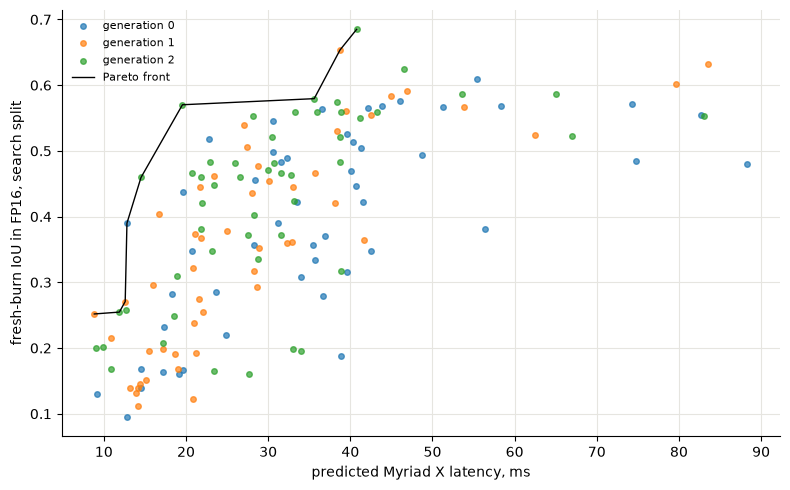

In [17]:
# [7] fitness against latency
fig, ax = plt.subplots(figsize=(8, 5))
report.plot_search(OUT, ax)
plt.tight_layout(); plt.show()

In [18]:
# [8] the winner
w = json.load(open(OUT / "winner.json")) if (OUT / "winner.json").exists() else {"winner": "not yet"}
print(json.dumps(w, indent=1, default=str))

{
 "gen": 2,
 "run": "r_b43b5741146f",
 "spec": "E:eb0:4/L:mb:48:3:4:silu:max/L:res:128:5:1:silu:max/D:conv:16:1",
 "score": 0.684887376828648,
 "score_pooled": 0.5066999353109695,
 "latency_ms": 40.766,
 "ir_mb": 2.484,
 "params": 1148302.0,
 "est_mb": 2.297,
 "minutes": 7.4458631793657934,
 "not_finite_steps": 0.0,
 "folded_pairs": 37.0,
 "trained": true,
 "heo_search_fp16_labels_fresh_iou": 0.5066999353109695,
 "heo_search_fp16_labels_mean_iou": 0.5144487253765873,
 "heo_search_fp16_labels_burn_iou": 0.1630695611414659,
 "heo_search_fp16_teacher_fresh_iou": 0.2033671440834952,
 "heo_search_fp16_teacher_mean_iou": 0.4222020039686493,
 "heo_search_fp16_teacher_burn_iou": 0.1814602468022764,
 "heo_search_fp32_labels_fresh_iou": 0.504723612808283,
 "heo_search_fp32_labels_mean_iou": 0.5142443823584015,
 "heo_search_fp32_labels_burn_iou": 0.1625245613790604,
 "heo_search_fp32_teacher_fresh_iou": 0.2044337895779295,
 "heo_search_fp32_teacher_mean_iou": 0.4224088946363735,
 "heo_search_fp3

Next: `08_final_and_test.ipynb`, the winner trained again with 3 seeds, baselines, ablations, export and test.